In [3]:
"""Run before code to install libraries"""
!pip install numpy scipy matplotlib

  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (11.0 MB)
Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (384 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [matplotlib]4 [matplotlib]


<>:85: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:87: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:85: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:87: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/tmp/ipykernel_20489/3993311252.py:85: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  axs[1].set_title("(b) Two-body Excess Entropy Contribution $\delta S_2^{ex}(r) / k_B$")
/tmp/ipykernel_20489/3993311252.py:87: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences wil

Converged S_2^ex / k_B for λ=0.5: -0.8379
Converged S_2^ex / k_B for λ=1.0: -1.1310
Converged S_2^ex / k_B for λ=2.0: -3.8532


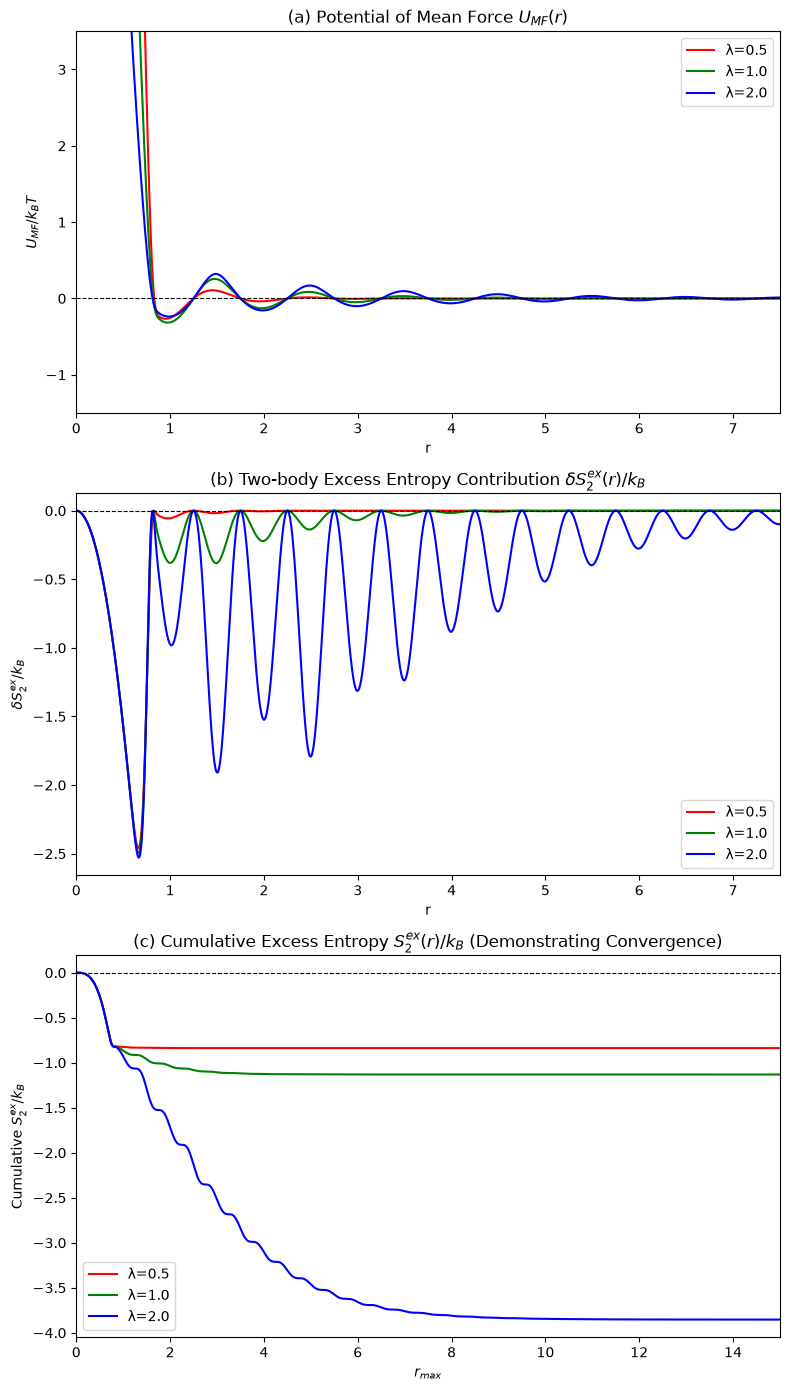

In [ ]:
""""Problem 1"""
import numpy as np
import matplotlib.pyplot as plt

def calc_g(r, lam):
    # radial distribution function
    core_repulsion = 1.0 - np.exp(-100.0 * r**20)
    attraction = 1.0 + np.cos(2.0 * np.pi * r) * np.exp(-r / lam)
    return core_repulsion * attraction

def calc_U_mf(g, lam):
    # Adding this here to stop log(0) errors by giving it a tiny floor value
    g_safe = np.where(g < 1e-12, 1e-12, g)
    return -(1.0 / lam) * np.log(g_safe)

def calc_delta_S2_ex(r, g, rho=1.0):
    #Calculates the dimensionless excess entropy contribution
    g_ln_g = np.zeros_like(g)
    mask = g > 1e-12
    g_ln_g[mask] = g[mask] * np.log(g[mask])
    return -2.0 * np.pi * rho * (r**2) * (g_ln_g - (g - 1.0))

def cumulative_trapezoidal_integral(x, y):
    
    #integration using the trapezoidal rule.
    #Spits out at array of the same length as x, which I'm using to calculate the integral from x[0] to x[i].
    #I'm not sure why, but the library technique I used in the last homework was hard to get to behave here
    integral = np.zeros_like(x)
    for i in range(1, len(x)):
        dx = x[i] - x[i-1]
        area = 0.5 * (y[i] + y[i-1]) * dx
        integral[i] = integral[i-1] + area
    return integral

# Control Panel
lambdas = [0.5, 1.0, 2.0]
colors = ['red', 'green', 'blue']
rho = 1.0
dr = 0.005

# Domain for parts (a) and (b)
r_plot = np.arange(0.0, 7.5 + dr, dr)

# Domain for part (c) - doubled to show that it converges
r_conv = np.arange(0.0, 15.0 + dr, dr)

#set up fig
fig, axs = plt.subplots(3, 1, figsize=(8, 14))

#Computing and Plotting Data
for lam, color in zip(lambdas, colors):
    
    #Part (A):
    g_plot = calc_g(r_plot, lam)
    U_mf_plot = calc_U_mf(g_plot, lam)
    
    # Shortening the y-axis for the hard-core singularity
    U_mf_plot = np.where(U_mf_plot > 5, np.nan, U_mf_plot)
    axs[0].plot(r_plot, U_mf_plot, color=color, label=f'λ={lam}')
    
    #(B): Excess entropy Contribution
    delta_S2_plot = calc_delta_S2_ex(r_plot, g_plot, rho)
    axs[1].plot(r_plot, delta_S2_plot, color=color, label=f'λ={lam}')
    
    #Part (C)Integral
    g_conv = calc_g(r_conv, lam)
    delta_S2_conv = calc_delta_S2_ex(r_conv, g_conv, rho)
    
    # Integrating to find S2_ex(r)
    S2_ex_cumulative = cumulative_trapezoidal_integral(r_conv, delta_S2_conv)
    axs[2].plot(r_conv, S2_ex_cumulative, color=color, label=f'λ={lam}')
    
    # Output
    final_S2_ex = S2_ex_cumulative[-1]
    print(f"Converged S_2^ex / k_B for λ={lam}: {final_S2_ex:.4f}")

# 4. Formatting Plots
axs[0].set_title("(a) Potential of Mean Force $U_{MF}(r)$")
axs[0].set_xlabel("r")
axs[0].set_ylabel("$U_{MF} / k_B T$")
axs[0].set_xlim(0, 7.5)
axs[0].set_ylim(-1.5, 3.5)
axs[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[0].legend()

axs[1].set_title("(b) Two-body Excess Entropy Contribution $\delta S_2^{ex}(r) / k_B$")
axs[1].set_xlabel("r")
axs[1].set_ylabel("$\delta S_2^{ex} / k_B$")
axs[1].set_xlim(0, 7.5)
axs[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[1].legend()

axs[2].set_title("(c) Cumulative Excess Entropy $S_2^{ex}(r) / k_B$ (Demonstrating Convergence)")
axs[2].set_xlabel("$r_{max}$")
axs[2].set_ylabel("Cumulative $S_2^{ex} / k_B$")
axs[2].set_xlim(0, 15.0)
axs[2].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[2].legend()

plt.tight_layout()
plt.show()

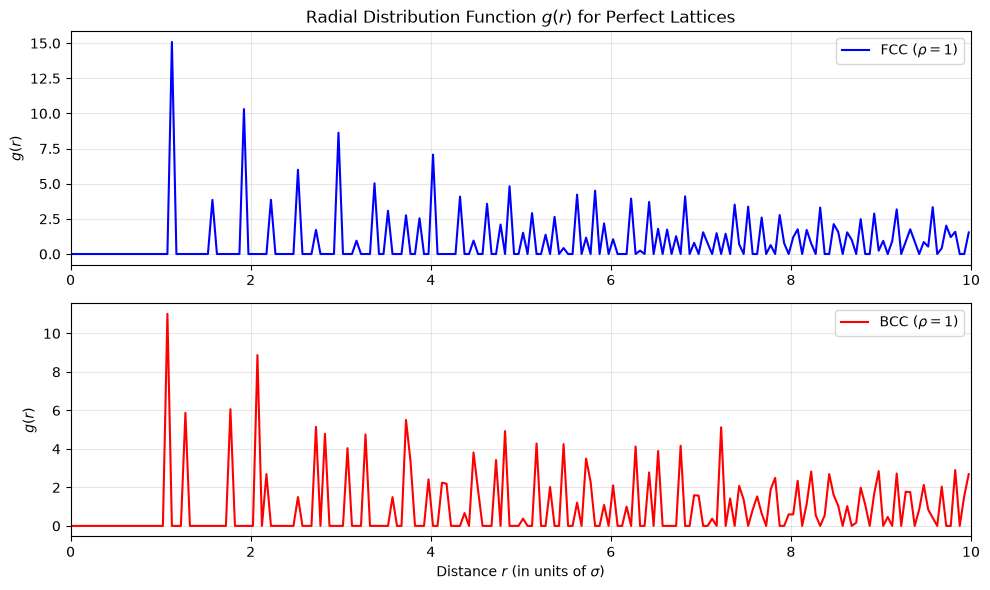

In [ ]:
"""Problem 2"""

import numpy as np
import matplotlib.pyplot as plt

def calculate_gr_lattice(lattice_type, rho=1.0, R_max=10.0, dr=0.05):
    if lattice_type == 'FCC':
        atoms_per_cell = 4
        a = (atoms_per_cell / rho) ** (1/3)
        basis = np.array([
            [0.0, 0.0, 0.0],
            [0.5, 0.5, 0.0],
            [0.5, 0.0, 0.5],
            [0.0, 0.5, 0.5]
        ]) * a
    elif lattice_type == 'BCC':
        atoms_per_cell = 2
        a = (atoms_per_cell / rho) ** (1/3)
        basis = np.array([
            [0.0, 0.0, 0.0],
            [0.5, 0.5, 0.5]
        ]) * a
    
    L_min = 2.0 * R_max
    N_cells = int(np.ceil(L_min / a))
    L_box = N_cells * a
    
    atoms = []
    for ix in range(N_cells):
        for iy in range(N_cells):
            for iz in range(N_cells):
                cell_origin = np.array([ix, iy, iz]) * a
                for b in basis:
                    atoms.append(cell_origin + b)
                    
    atoms = np.array(atoms)
    reference_atom = atoms[0]
    dr_vectors = atoms - reference_atom
    
    # Using Minimum Image Convention
    dr_vectors = dr_vectors - L_box * np.round(dr_vectors / L_box)
    distances = np.linalg.norm(dr_vectors, axis=1)
    distances = distances[distances > 0.001] 
    
    bins = np.arange(0, R_max + dr, dr)
    counts, bin_edges = np.histogram(distances, bins=bins)
    r_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
    
    shell_volumes = (4.0 / 3.0) * np.pi * (bin_edges[1:]**3 - bin_edges[:-1]**3)
    ideal_counts = rho * shell_volumes
    g_r = np.zeros_like(counts, dtype=float)
    nonzero = ideal_counts > 0
    g_r[nonzero] = counts[nonzero] / ideal_counts[nonzero]
    
    return r_centers, g_r

#Control Panel
rho_val = 1.0
R_max_val = 10.0
bin_width = 0.05 

#driver code
r_fcc, gr_fcc = calculate_gr_lattice('FCC', rho=rho_val, R_max=R_max_val, dr=bin_width)
r_bcc, gr_bcc = calculate_gr_lattice('BCC', rho=rho_val, R_max=R_max_val, dr=bin_width)

plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(r_fcc, gr_fcc, color='blue', label='FCC ($\u03C1=1$)')
plt.title('Radial Distribution Function $g(r)$ for Perfect Lattices')
plt.ylabel('$g(r)$')
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(r_bcc, gr_bcc, color='red', label='BCC ($\u03C1=1$)')
plt.xlabel('Distance $r$ (in units of $\u03C3$)')
plt.ylabel('$g(r)$')
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

<>:70: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:70: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:81: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:81: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:83: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:70: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:70: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences wil

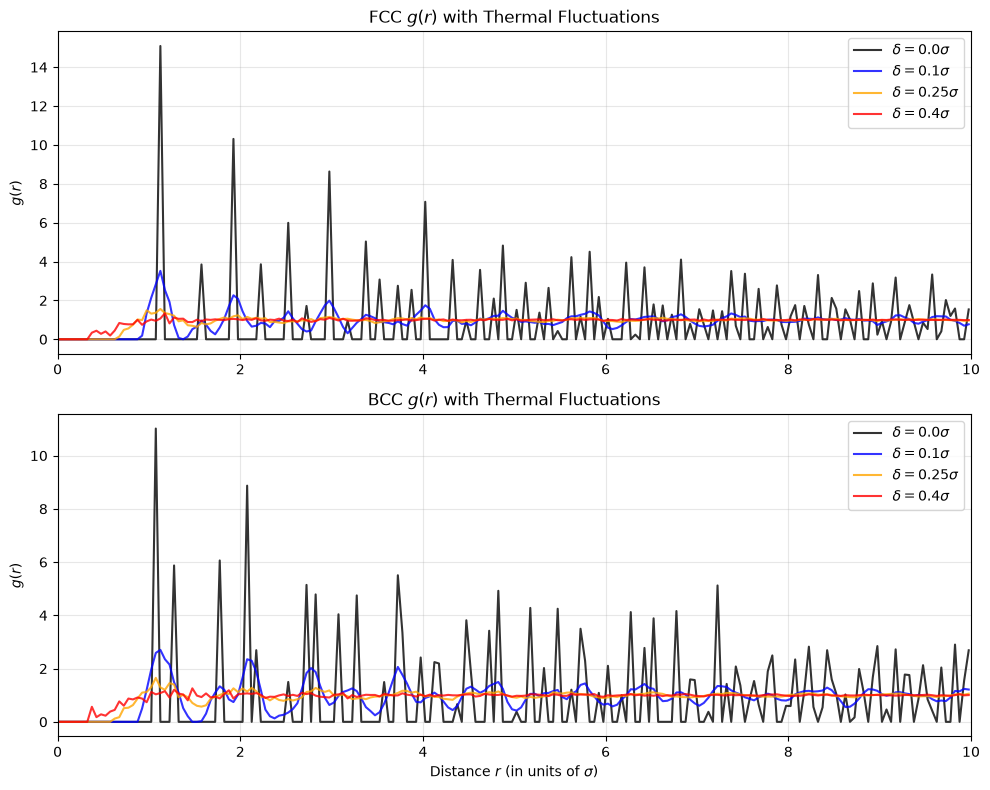

In [10]:
"""Problem 3"""
import numpy as np
import matplotlib.pyplot as plt

def calculate_gr_fluctuating(lattice_type, delta, rho=1.0, R_max=10.0, dr=0.05, num_refs=100):
    if lattice_type == 'FCC':
        atoms_per_cell = 4
        a = (atoms_per_cell / rho) ** (1/3)
        basis = np.array([[0.0, 0.0, 0.0], [0.5, 0.5, 0.0], [0.5, 0.0, 0.5], [0.0, 0.5, 0.5]]) * a
    elif lattice_type == 'BCC':
        atoms_per_cell = 2
        a = (atoms_per_cell / rho) ** (1/3)
        basis = np.array([[0.0, 0.0, 0.0], [0.5, 0.5, 0.5]]) * a
    
    L_min = 2.0 * R_max
    N_cells = int(np.ceil(L_min / a))
    L_box = N_cells * a
    
    atoms = []
    for ix in range(N_cells):
        for iy in range(N_cells):
            for iz in range(N_cells):
                cell_origin = np.array([ix, iy, iz]) * a
                for b in basis:
                    atoms.append(cell_origin + b)
                    
    atoms = np.array(atoms)
    
    if delta > 0:
        noise = np.random.normal(0, 1, size=atoms.shape)
        norms = np.linalg.norm(noise, axis=1, keepdims=True)
        unit_vectors = noise / norms
        atoms += delta * unit_vectors
    
    # Calculating distances from a sample of atoms to account for broken symmetry
    all_distances = []
    for i in range(num_refs):
        ref_atom = atoms[i]
        dr_vectors = atoms - ref_atom
        dr_vectors = dr_vectors - L_box * np.round(dr_vectors / L_box)
        
        dist = np.linalg.norm(dr_vectors, axis=1)
        dist = dist[dist > 0.001]
        all_distances.extend(dist)
        
    bins = np.arange(0, R_max + dr, dr)
    counts, bin_edges = np.histogram(all_distances, bins=bins)
    r_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
    shell_volumes = (4.0 / 3.0) * np.pi * (bin_edges[1:]**3 - bin_edges[:-1]**3)
    ideal_counts = num_refs * rho * shell_volumes
    
    g_r = np.zeros_like(counts, dtype=float)
    nonzero = ideal_counts > 0
    g_r[nonzero] = counts[nonzero] / ideal_counts[nonzero]
    
    return r_centers, g_r

rho_val = 1.0
R_max_val = 10.0
bin_width = 0.05
deltas = [0.0, 0.1, 0.25, 0.4]
colors = ['black', 'blue', 'orange', 'red']

plt.figure(figsize=(10, 8))

# FCC Plot
plt.subplot(2, 1, 1)
for delta, color in zip(deltas, colors):
    r, gr = calculate_gr_fluctuating('FCC', delta, rho=rho_val, R_max=R_max_val, dr=bin_width)
    plt.plot(r, gr, color=color, alpha=0.8, label=f'$\delta={delta}\sigma$')
plt.title('FCC $g(r)$ with Thermal Fluctuations')
plt.ylabel('$g(r)$')
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.legend()

# BCC Plot
plt.subplot(2, 1, 2)
for delta, color in zip(deltas, colors):
    r, gr = calculate_gr_fluctuating('BCC', delta, rho=rho_val, R_max=R_max_val, dr=bin_width)
    plt.plot(r, gr, color=color, alpha=0.8, label=f'$\delta={delta}\sigma$')
plt.title('BCC $g(r)$ with Thermal Fluctuations')
plt.xlabel('Distance $r$ (in units of $\sigma$)')
plt.ylabel('$g(r)$')
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()